In [1]:
import sys 
import os

# Data analysis & stats
import pandas as pd
import numpy as np
from scipy.stats import ranksums
from scipy.sparse import csr_matrix
from scipy.stats import ttest_ind


from sklearn.preprocessing import MinMaxScaler, RobustScaler

from scipy import sparse

# Single-cell
import scanpy as sc
import scanpy.external as sce
import anndata

# Plotting & palettes
import matplotlib.pyplot as plt
import seaborn as sns
from palettable.cartocolors.qualitative import Pastel_10, Safe_10, Bold_10, Vivid_10, Prism_10, Antique_5
from palettable.colorbrewer.qualitative import Set3_12

sys.path.append('../../')
from stacked_barplots import plot_stacked_bar

sys.path.append('/media/amon/2TB-HD/Olga/Aging_and_transcriptional_noise/tools')
import transcriptional_noise as tn

seed=10

In [35]:
metadata = pd.read_csv('../../data/raw_data/ximerakis/GSE129788_Supplementary_meta_data_Cell_Types_Etc.txt.gz', sep='\t', index_col=0)
metadata = metadata.iloc[1:, :]

In [3]:
gsm_list = [fname.split('_')[0] for fname in os.listdir('../../data/raw_data/ximerakis/gsm')]

In [4]:
def create_annData(filename): 
    adata = sc.read_csv(f'../../data/raw_data/ximerakis/gsm/{filename}', delimiter='\t').transpose()
    
    gsm, batch = filename.split('_')[0], filename.split('_')[1]
    adata.obs['gsm'] = gsm
    adata.obs['batch'] = batch
    return adata

In [5]:
adata_list = [create_annData(filename) for filename in os.listdir('../../data/raw_data/ximerakis/gsm')]

In [6]:
adata = sc.AnnData.concatenate(*adata_list, batch_categories=gsm_list)

In [7]:
sc.pp.normalize_total(adata, target_sum=1e4)

In [8]:
sc.pp.log1p(adata)

In [9]:
sc.pp.highly_variable_genes(adata, min_mean=0.0125, max_mean=4, min_disp=0.5)

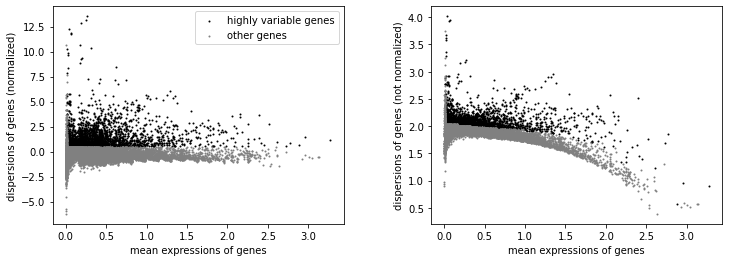

In [10]:
sc.pl.highly_variable_genes(adata)

In [11]:
sc.pp.pca(adata)

/home/amon/anaconda3/lib/python3.7/site-packages/anndata/_core/anndata.py:1220: FutureWarning: The `inplace` parameter in pandas.Categorical.reorder_categories is deprecated and will be removed in a future version. Removing unused categories will always return a new Categorical object.
  c.reorder_categories(natsorted(c.categories), inplace=True)
... storing 'gsm' as categorical


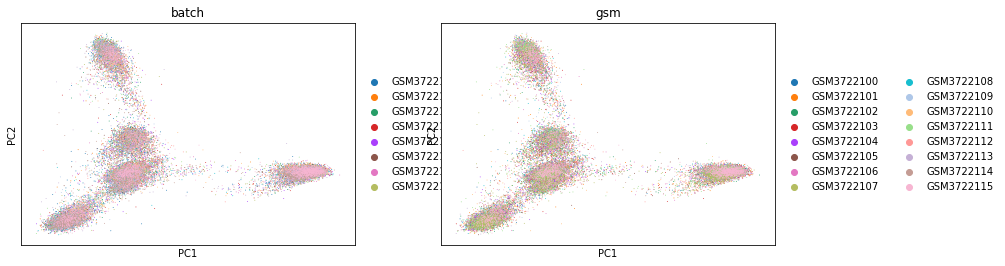

In [12]:
sc.pl.pca(adata, color=['batch', 'gsm'])

In [13]:
sce.pp.harmony_integrate(adata, key='batch')

2021-11-03 11:59:29,573 - harmonypy - INFO - Iteration 1 of 10
2021-11-03 11:59:58,833 - harmonypy - INFO - Iteration 2 of 10
2021-11-03 12:00:28,795 - harmonypy - INFO - Iteration 3 of 10
2021-11-03 12:00:59,001 - harmonypy - INFO - Iteration 4 of 10
2021-11-03 12:01:31,390 - harmonypy - INFO - Iteration 5 of 10
2021-11-03 12:01:43,213 - harmonypy - INFO - Iteration 6 of 10
2021-11-03 12:01:55,961 - harmonypy - INFO - Iteration 7 of 10
2021-11-03 12:02:06,375 - harmonypy - INFO - Iteration 8 of 10
2021-11-03 12:02:19,989 - harmonypy - INFO - Converged after 8 iterations


In [14]:
sc.pp.neighbors(adata, use_rep='X_pca_harmony')

In [15]:
sc.tl.umap(adata)

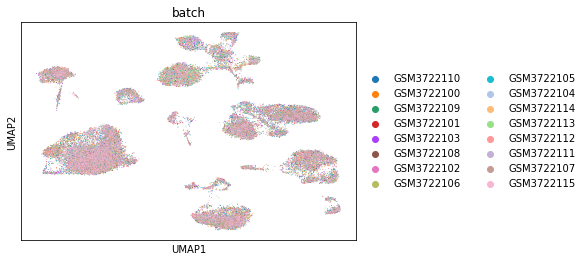

In [17]:
sc.pl.umap(adata, color=['batch'], ncols=2)

In [18]:
adata

AnnData object with n_obs × n_vars = 37069 × 14699
    obs: 'gsm', 'batch'
    var: 'highly_variable', 'means', 'dispersions', 'dispersions_norm'
    uns: 'log1p', 'hvg', 'pca', 'batch_colors', 'gsm_colors', 'neighbors', 'umap'
    obsm: 'X_pca', 'X_pca_harmony', 'X_umap'
    varm: 'PCs'
    obsp: 'distances', 'connectivities'

In [21]:
set(adata.obs['gsm'])

16

In [36]:
metadata.loc[:, 'cell_classes']

NAME
Aging_mouse_brain_portal_data_6_AAACCTGAGGCCCTTG     IMMUNE_Lin
Aging_mouse_brain_portal_data_6_AAACGGGAGAGACGAA     IMMUNE_Lin
Aging_mouse_brain_portal_data_6_AAAGTAGCAACGATCT     IMMUNE_Lin
Aging_mouse_brain_portal_data_6_AACCGCGCAACAACCT     IMMUNE_Lin
Aging_mouse_brain_portal_data_6_AACTCCCAGTACGTAA     IMMUNE_Lin
                                                        ...    
Aging_mouse_brain_portal_data_43_GCACATATCCGTAGTA    IMMUNE_Lin
Aging_mouse_brain_portal_data_44_AGCTCTCCAATGTAAG    IMMUNE_Lin
Aging_mouse_brain_portal_data_44_CATCGAACAAACGCGA    IMMUNE_Lin
Aging_mouse_brain_portal_data_44_GGGATGATCTCCTATA    IMMUNE_Lin
Aging_mouse_brain_portal_data_44_TGAAAGACAGACAAGC    IMMUNE_Lin
Name: cell_classes, Length: 37069, dtype: object

In [40]:
cell_names = ['_'.join(ind.split('_')[-2:]) for ind in metadata.index]
metadata.index = cell_names

In [51]:
adata.obs_names = [nam.split('-')[0] for nam in adata.obs_names]

In [56]:
adata.obs['condition'] = metadata.loc[adata.obs_names, 'animal_type']
adata.obs['cell_type'] = metadata.loc[adata.obs_names, 'cluster']
adata.obs['cell_class'] = metadata.loc[adata.obs_names, 'cell_classes']

In [ ]:
adata.obs['condition'] = [age.capitalize() for age in adata.obs['condition']]

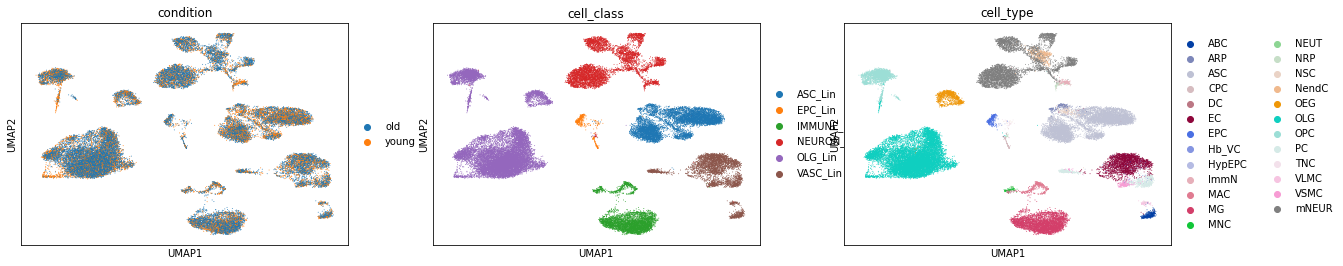

In [58]:
sc.pl.umap(adata, color=['condition', 'cell_class', 'cell_type'])

In [59]:
adata.write('../../data/anndatas/annotated/Ximerakis.h5ad')